In [1]:
import os
import sys
import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Suppress minor warnings for clean notebook logs
warnings.filterwarnings("ignore")

# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Project Directory Setup (matches your exact AI_Image_Project paths)
BASE_DIR = Path("/content/drive/MyDrive/AI_Image_Project")
FEATURES_DIR = BASE_DIR / "features"
RESULTS_DIR = BASE_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"

FEATURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("PROJECT ENVIRONMENT INITIALIZED")
print("=" * 70)
print(f"Base Directory    : {BASE_DIR}")
print(f"Features Directory: {FEATURES_DIR}")
print(f"Results Directory : {RESULTS_DIR}")

Mounted at /content/drive
PROJECT ENVIRONMENT INITIALIZED
Base Directory    : /content/drive/MyDrive/AI_Image_Project
Features Directory: /content/drive/MyDrive/AI_Image_Project/features
Results Directory : /content/drive/MyDrive/AI_Image_Project/results


In [2]:
# Image size for handcrafted features (128x128 provides maximum speed while preserving artifacts)
IMAGE_SIZE = (128, 128)

# Directory mapping for the 3 classes (5,000 images per class = 15,000 total)
CLASS_DIRS = {
    0: BASE_DIR / "COCO_5000",                       # Class 0: 100% Authentic
    1: BASE_DIR / "DiffusionDB_5000",                # Class 1: 100% AI-Generated
    2: BASE_DIR / "Partial_AI_5000" / "Manipulated"   # Class 2: Partially AI-Manipulated
}

CLASS_NAMES = {
    0: "Authentic (COCO)",
    1: "Full AI (DiffusionDB)",
    2: "Partial AI (Manipulated)"
}

VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

# Collect all image paths and labels
all_file_paths = []
all_file_labels = []

print("Scanning dataset directories...")
for label, folder in CLASS_DIRS.items():
    if not folder.exists():
        print(f"  [ERROR] Folder not found: {folder}")
        continue

    # Collect files deterministically
    files = [
        str(folder / entry.name)
        for entry in os.scandir(folder)
        if entry.is_file() and entry.name.lower().endswith(VALID_EXTENSIONS)
    ]
    files = sorted(files)[:5000] # Ensure exactly balanced 5,000 images per class

    all_file_paths.extend(files)
    all_file_labels.extend([label] * len(files))
    print(f"  [Class {label}] {CLASS_NAMES[label]:<28}: {len(files):>5} images found")

all_file_paths = np.array(all_file_paths, dtype=object)
all_file_labels = np.array(all_file_labels, dtype=np.int64)

print("-" * 70)
print(f"Total Dataset Inventory: {len(all_file_paths)} images")

Scanning dataset directories...
  [Class 0] Authentic (COCO)            :  5000 images found
  [Class 1] Full AI (DiffusionDB)       :  5000 images found
  [Class 2] Partial AI (Manipulated)    :  5000 images found
----------------------------------------------------------------------
Total Dataset Inventory: 15000 images


In [3]:
def make_stratified_split(labels, train_pct=0.80, val_pct=0.10, seed=42):
    """
    Splits indices into Train / Val / Test in pure NumPy.
    Guarantees perfectly balanced class proportions across every split.
    """
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []

    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        rng.shuffle(c_indices)

        n_total = len(c_indices)
        n_train = int(round(n_total * train_pct))
        n_val = int(round(n_total * val_pct))

        train_idx.extend(c_indices[:n_train])
        val_idx.extend(c_indices[n_train:n_train + n_val])
        test_idx.extend(c_indices[n_train + n_val:])

    train_idx = np.array(sorted(train_idx), dtype=np.int64)
    val_idx = np.array(sorted(val_idx), dtype=np.int64)
    test_idx = np.array(sorted(test_idx), dtype=np.int64)

    # Verification checks
    assert len(np.intersect1d(train_idx, val_idx)) == 0, "Leakage between train and val!"
    assert len(np.intersect1d(train_idx, test_idx)) == 0, "Leakage between train and test!"
    assert len(np.intersect1d(val_idx, test_idx)) == 0, "Leakage between val and test!"

    return train_idx, val_idx, test_idx

train_idx, val_idx, test_idx = make_stratified_split(all_file_labels, 0.80, 0.10, seed=42)

# Save split indices permanently for fair comparison across all upcoming notebooks
np.save(FEATURES_DIR / "train_idx.npy", train_idx)
np.save(FEATURES_DIR / "val_idx.npy", val_idx)
np.save(FEATURES_DIR / "test_idx.npy", test_idx)
np.save(FEATURES_DIR / "y_labels_15k.npy", all_file_labels)

print("Stratified Data Split Generated & Saved Successfully:")
print(f"  Training Set   : {len(train_idx):>5} samples ({len(train_idx)/len(all_file_labels)*100:.1f}%) | Classes: {np.bincount(all_file_labels[train_idx])}")
print(f"  Validation Set : {len(val_idx):>5} samples ({len(val_idx)/len(all_file_labels)*100:.1f}%) | Classes: {np.bincount(all_file_labels[val_idx])}")
print(f"  Test Set       : {len(test_idx):>5} samples ({len(test_idx)/len(all_file_labels)*100:.1f}%) | Classes: {np.bincount(all_file_labels[test_idx])}")

Stratified Data Split Generated & Saved Successfully:
  Training Set   : 12000 samples (80.0%) | Classes: [4000 4000 4000]
  Validation Set :  1500 samples (10.0%) | Classes: [500 500 500]
  Test Set       :  1500 samples (10.0%) | Classes: [500 500 500]


In [4]:
# Precomputed radial coordinate maps for ultra-fast 2D FFT features
_Y, _X = np.ogrid[:128, :128]
_RADIUS_MAP = np.sqrt((_X - 64) ** 2 + (_Y - 64) ** 2)
_ANGLE_MAP = np.arctan2(_Y - 64, _X - 64)

def calculate_skew_kurtosis(arr):
    """Computes sample skewness and kurtosis in pure NumPy."""
    flat = arr.ravel()
    mean_val = np.mean(flat)
    std_val = np.std(flat) + 1e-8
    z = (flat - mean_val) / std_val
    skew = np.mean(z ** 3)
    kurt = np.mean(z ** 4) - 3.0
    return float(skew), float(kurt)

def extract_domain1_spatial(img_rgb, gray):
    """Global spatial channel stats and cross-channel correlations (36 features)."""
    feats = []
    channels = [img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2], gray]
    for ch in channels:
        s, k = calculate_skew_kurtosis(ch)
        feats.extend([
            float(np.mean(ch)), float(np.std(ch)), float(np.var(ch)),
            float(np.min(ch)), float(np.max(ch)), float(np.median(ch)),
            s, k
        ])

    r_flat = img_rgb[:, :, 0].ravel()
    g_flat = img_rgb[:, :, 1].ravel()
    b_flat = img_rgb[:, :, 2].ravel()

    c_rg = np.corrcoef(r_flat, g_flat)[0, 1] if np.std(r_flat) > 1e-6 and np.std(g_flat) > 1e-6 else 0.0
    c_rb = np.corrcoef(r_flat, b_flat)[0, 1] if np.std(r_flat) > 1e-6 and np.std(b_flat) > 1e-6 else 0.0
    c_gb = np.corrcoef(g_flat, b_flat)[0, 1] if np.std(g_flat) > 1e-6 and np.std(b_flat) > 1e-6 else 0.0
    rg_diff_std = float(np.std(img_rgb[:, :, 0] - img_rgb[:, :, 1]))

    feats.extend([float(np.nan_to_num(c_rg)), float(np.nan_to_num(c_rb)), float(np.nan_to_num(c_gb)), rg_diff_std])
    return feats

def extract_domain2_histograms(img_rgb, gray):
    """Intensity histograms across RGB and grayscale (128 features)."""
    feats = []
    channels = [img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2], gray]
    for ch in channels:
        hist, _ = np.histogram(ch, bins=32, range=(0.0, 1.0), density=False)
        hist = hist.astype(np.float32) / (ch.size + 1e-8)
        feats.extend(hist.tolist())
    return feats

def extract_domain3_fft(gray):
    """2D FFT spectral radial rings and angular wedges (64 features)."""
    feats = []
    fft_shift = np.fft.fftshift(np.fft.fft2(gray))
    mag = np.log1p(np.abs(fft_shift))

    # Global stats
    s, k = calculate_skew_kurtosis(mag)
    feats.extend([
        float(np.mean(mag)), float(np.std(mag)), float(np.max(mag)), float(np.min(mag)),
        float(np.percentile(mag, 25)), float(np.percentile(mag, 50)),
        float(np.percentile(mag, 75)), float(np.percentile(mag, 95))
    ])

    # 16 Concentric rings
    edges = np.linspace(0, 64.0, 17)
    for i in range(16):
        mask = (_RADIUS_MAP >= edges[i]) & (_RADIUS_MAP < edges[i + 1])
        vals = mag[mask]
        if len(vals) > 0:
            feats.extend([float(np.mean(vals)), float(np.std(vals)), float(np.max(vals))])
        else:
            feats.extend([0.0, 0.0, 0.0])

    # 4 Angular wedges
    ang_edges = np.linspace(-np.pi, np.pi, 5)
    for i in range(4):
        mask = (_ANGLE_MAP >= ang_edges[i]) & (_ANGLE_MAP < ang_edges[i + 1]) & (_RADIUS_MAP > 5)
        vals = mag[mask]
        feats.extend([float(np.mean(vals)), float(np.std(vals))])

    return feats

def extract_domain4_residuals(img_rgb, gray):
    """Sensor noise residuals and SRM spatial high-pass filters (68 features)."""
    feats = []
    smooth = (
        np.roll(gray, 1, axis=0) + np.roll(gray, -1, axis=0) +
        np.roll(gray, 1, axis=1) + np.roll(gray, -1, axis=1)
    ) / 4.0
    res_lap = gray - smooth
    res_h = gray - np.roll(gray, 1, axis=1)
    res_v = gray - np.roll(gray, 1, axis=0)
    res_d = (gray + np.roll(np.roll(gray, 1, 0), 1, 1)) - (np.roll(gray, 1, 0) + np.roll(gray, 1, 1))

    for r in [res_lap, res_h, res_v, res_d]:
        s, k = calculate_skew_kurtosis(r)
        abs_r = np.abs(r)
        feats.extend([
            float(np.mean(r)), float(np.std(r)), float(np.var(r)),
            float(np.mean(abs_r)), float(np.std(abs_r)),
            float(np.max(r)), float(np.min(r)), s, k,
            float(np.percentile(r, 5)), float(np.percentile(r, 25)),
            float(np.percentile(r, 50)), float(np.percentile(r, 75)),
            float(np.percentile(r, 95))
        ])

    for c in range(3):
        ch = img_rgb[:, :, c]
        ch_res = ch - (np.roll(ch, 1, 0) + np.roll(ch, -1, 0) + np.roll(ch, 1, 1) + np.roll(ch, -1, 1)) / 4.0
        feats.extend([
            float(np.mean(np.abs(ch_res))), float(np.std(ch_res)),
            float(np.percentile(ch_res, 90)), float(np.percentile(ch_res, 10))
        ])

    return feats, res_lap

def extract_domain5_gradients(gray):
    """Gradients and 4-bit Local Binary Pattern (LBP) histogram (60 features)."""
    feats = []
    gx = np.roll(gray, -1, axis=1) - np.roll(gray, 1, axis=1)
    gy = np.roll(gray, -1, axis=0) - np.roll(gray, 1, axis=0)
    g_mag = np.sqrt(gx ** 2 + gy ** 2)
    g_ori = np.arctan2(gy, gx)

    s, k = calculate_skew_kurtosis(g_mag)
    feats.extend([
        float(np.mean(g_mag)), float(np.std(g_mag)), float(np.var(g_mag)),
        float(np.max(g_mag)), float(np.median(g_mag)), s, k,
        float(np.percentile(g_mag, 10)), float(np.percentile(g_mag, 25)),
        float(np.percentile(g_mag, 75)), float(np.percentile(g_mag, 90)),
        float(np.percentile(g_mag, 99))
    ])

    h_mag, _ = np.histogram(g_mag, bins=16, range=(0.0, 1.5), density=False)
    feats.extend((h_mag.astype(np.float32) / (g_mag.size + 1e-8)).tolist())

    h_ori, _ = np.histogram(g_ori, bins=16, range=(-np.pi, np.pi), density=False)
    feats.extend((h_ori.astype(np.float32) / (g_ori.size + 1e-8)).tolist())

    # 4-bit LBP
    b0 = (gray > np.roll(gray, 1, 0)).astype(np.int32)
    b1 = (gray > np.roll(gray, -1, 0)).astype(np.int32) * 2
    b2 = (gray > np.roll(gray, 1, 1)).astype(np.int32) * 4
    b3 = (gray > np.roll(gray, -1, 1)).astype(np.int32) * 8
    lbp = b0 + b1 + b2 + b3
    lbp_h, _ = np.histogram(lbp, bins=16, range=(0, 16), density=False)
    feats.extend((lbp_h.astype(np.float32) / (gray.size + 1e-8)).tolist())

    return feats, g_mag

def extract_domain6_patches(img_rgb, gray, res_lap, g_mag):
    """16 Local 32x32 patches for detecting splicing/inpainting seams (480 features)."""
    feats = []
    p_h, p_w = 32, 32
    for r in range(4):
        for c in range(4):
            y0, y1 = r * p_h, (r + 1) * p_h
            x0, x1 = c * p_w, (c + 1) * p_w

            p_rgb = img_rgb[y0:y1, x0:x1]
            p_gray = gray[y0:y1, x0:x1]
            p_res = res_lap[y0:y1, x0:x1]
            p_grad = g_mag[y0:y1, x0:x1]

            # Patch color
            for ch in range(3):
                feats.extend([float(np.mean(p_rgb[:, :, ch])), float(np.std(p_rgb[:, :, ch]))])
            feats.extend([float(np.mean(p_gray)), float(np.std(p_gray))])

            # Patch noise
            s, k = calculate_skew_kurtosis(p_res)
            abs_res = np.abs(p_res)
            feats.extend([
                float(np.mean(p_res)), float(np.std(p_res)), float(np.var(p_res)),
                float(np.mean(abs_res)), float(np.max(abs_res)), s, k,
                float(np.percentile(p_res, 10)), float(np.percentile(p_res, 50)),
                float(np.percentile(p_res, 90))
            ])

            # Patch gradient
            feats.extend([
                float(np.mean(p_grad)), float(np.std(p_grad)), float(np.max(p_grad)),
                float(np.percentile(p_grad, 25)), float(np.percentile(p_grad, 50)),
                float(np.percentile(p_grad, 90))
            ])

            # Patch spectral
            p_fft = np.fft.fftshift(np.fft.fft2(p_gray))
            p_mag = np.log1p(np.abs(p_fft))
            low_f = p_mag[12:20, 12:20]
            high_f = p_mag[:8, :8]
            feats.extend([
                float(np.mean(p_mag)), float(np.std(p_mag)),
                float(np.mean(low_f)), float(np.std(low_f)),
                float(np.mean(high_f)), float(np.std(high_f))
            ])

    return feats

def extract_all_handcrafted_features(image_path):
    """Master single-image extractor returning a clean (836,) vector."""
    try:
        with Image.open(image_path) as img:
            rgb = img.convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
            arr = np.asarray(rgb, dtype=np.float32) / 255.0

        gray = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]

        f1 = extract_domain1_spatial(arr, gray)
        f2 = extract_domain2_histograms(arr, gray)
        f3 = extract_domain3_fft(gray)
        f4, res_lap = extract_domain4_residuals(arr, gray)
        f5, g_mag = extract_domain5_gradients(gray)
        f6 = extract_domain6_patches(arr, gray, res_lap, g_mag)

        vector = f1 + f2 + f3 + f4 + f5 + f6
        return np.nan_to_num(np.array(vector, dtype=np.float32), nan=0.0)
    except Exception:
        return np.zeros(836, dtype=np.float32)

print("836-Feature Forensic Extractor compiled successfully.")

836-Feature Forensic Extractor compiled successfully.


In [5]:
from concurrent.futures import ProcessPoolExecutor
from tqdm.notebook import tqdm

X_HAND_PATH = FEATURES_DIR / "X_handcrafted_836.npy"

if X_HAND_PATH.exists():
    print(f"Loading cached handcrafted feature matrix: {X_HAND_PATH}")
    X_handcrafted = np.load(X_HAND_PATH)
    print(f"  Shape: {X_handcrafted.shape}")
else:
    num_images = len(all_file_paths)
    print(f"Extracting 836 handcrafted features for {num_images} images...")
    print(f"Bypassing Python GIL using ProcessPoolExecutor on {os.cpu_count()} CPU cores...")

    start_time = time.time()

    # ProcessPoolExecutor achieves true parallel core saturation
    with ProcessPoolExecutor(max_workers=os.cpu_count()) as executor:
        results = list(tqdm(
            executor.map(extract_all_handcrafted_features, all_file_paths, chunksize=50),
            total=num_images,
            desc="Extracting Handcrafted Features"
        ))

    X_handcrafted = np.array(results, dtype=np.float32)
    elapsed = time.time() - start_time

    print(f"\nHandcrafted feature extraction complete in {elapsed / 60:.2f} minutes!")
    print(f"Matrix shape: {X_handcrafted.shape}")

    np.save(X_HAND_PATH, X_handcrafted)
    print(f"Saved: {X_HAND_PATH}")

Extracting 836 handcrafted features for 15000 images...
Bypassing Python GIL using ProcessPoolExecutor on 2 CPU cores...


Extracting Handcrafted Features:   0%|          | 0/15000 [00:00<?, ?it/s]


Handcrafted feature extraction complete in 54.84 minutes!
Matrix shape: (15000, 836)
Saved: /content/drive/MyDrive/AI_Image_Project/features/X_handcrafted_836.npy


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModel

X_DINO_PATH = FEATURES_DIR / "X_dinov2_768.npy"
DINO_MODEL_NAME = "facebook/dinov2-base"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if X_DINO_PATH.exists():
    print(f"Loading cached DINOv2 features: {X_DINO_PATH}")
    X_dino = np.load(X_DINO_PATH)
    print(f"  Shape: {X_dino.shape}")
else:
    print(f"Loading Frozen DINOv2 Backbone ({DINO_MODEL_NAME}) on {DEVICE}...")
    processor = AutoImageProcessor.from_pretrained(DINO_MODEL_NAME)
    dino_model = AutoModel.from_pretrained(DINO_MODEL_NAME).to(DEVICE)

    # Strictly freeze weights so it acts only as an inference feature engine
    dino_model.eval()
    for p in dino_model.parameters():
        p.requires_grad = False

    class FastDinoDataset(Dataset):
        def __init__(self, file_paths, proc):
            self.file_paths = file_paths
            self.proc = proc

        def __len__(self):
            return len(self.file_paths)

        def __getitem__(self, idx):
            p = self.file_paths[idx]
            try:
                with Image.open(p) as img:
                    rgb = img.convert("RGB")
                    inputs = self.proc(images=rgb, return_tensors="pt")
                    return inputs["pixel_values"].squeeze(0)
            except Exception:
                return torch.zeros((3, 224, 224), dtype=torch.float32)

    batch_sz = 64 if torch.cuda.is_available() else 16
    dino_dataset = FastDinoDataset(all_file_paths, processor)
    dino_loader = DataLoader(
        dino_dataset,
        batch_size=batch_sz,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    cls_embeddings = []
    t0 = time.time()
    print(f"Extracting DINOv2 CLS embeddings (Batch size = {batch_sz})...")

    with torch.no_grad():
        for batch_pixels in tqdm(dino_loader, desc="DINOv2 GPU Forward Passes"):
            batch_pixels = batch_pixels.to(DEVICE, non_blocking=True)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                outputs = dino_model(pixel_values=batch_pixels)
                # CLS token sits at token index 0
                cls_tokens = outputs.last_hidden_state[:, 0, :].float().cpu().numpy()
            cls_embeddings.append(cls_tokens)

    X_dino = np.vstack(cls_embeddings).astype(np.float32)
    print(f"\nDINOv2 extraction complete in {time.time() - t0:.1f} seconds! Shape: {X_dino.shape}")

    np.save(X_DINO_PATH, X_dino)
    print(f"Saved: {X_DINO_PATH}")

    # Free up GPU memory
    del dino_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Loading Frozen DINOv2 Backbone (facebook/dinov2-base) on cuda...


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting DINOv2 CLS embeddings (Batch size = 64)...


DINOv2 GPU Forward Passes:   0%|          | 0/235 [00:00<?, ?it/s]


DINOv2 extraction complete in 269.9 seconds! Shape: (15000, 768)
Saved: /content/drive/MyDrive/AI_Image_Project/features/X_dinov2_768.npy


In [7]:
# 1. Concatenate into full feature matrix (836 + 768 = 1,604 dimensions)
X_combined_1604 = np.hstack([X_handcrafted, X_dino]).astype(np.float32)
print(f"Full Combined Feature Matrix Shape: {X_combined_1604.shape}")

# 2. Vectorized One-Way ANOVA F-Score computed STRICTLY on train_idx
def compute_anova_f_scores_vectorized(X_tr, y_tr):
    """
    Computes One-Way ANOVA F-test scores in pure NumPy.
    Completely vectorized across all features simultaneously.
    """
    N, P = X_tr.shape
    classes = np.unique(y_tr)
    K = len(classes)

    grand_mean = np.mean(X_tr, axis=0)
    ss_between = np.zeros(P, dtype=np.float64)
    ss_within = np.zeros(P, dtype=np.float64)

    for c in classes:
        X_c = X_tr[y_tr == c]
        n_c = X_c.shape[0]
        mean_c = np.mean(X_c, axis=0)
        ss_between += n_c * ((mean_c - grand_mean) ** 2)
        ss_within += np.sum((X_c - mean_c) ** 2, axis=0)

    ms_between = ss_between / (K - 1)
    ms_within = ss_within / (N - K + 1e-12)
    f_scores = ms_between / (ms_within + 1e-12)

    return np.nan_to_num(f_scores, nan=0.0).astype(np.float32)

print("\nComputing One-Way ANOVA F-scores across all 1,604 features using training split ONLY...")
train_features = X_combined_1604[train_idx]
train_labels = all_file_labels[train_idx]

f_scores = compute_anova_f_scores_vectorized(train_features, train_labels)

# 3. Select Top 500 features with highest discriminative power
TOP_K = 500
top500_indices = np.argsort(f_scores)[::-1][:TOP_K]

X_combined_500 = X_combined_1604[:, top500_indices]

# Count how many features from each origin made the cut
handcrafted_count = int(np.sum(top500_indices < 836))
dino_count = int(np.sum(top500_indices >= 836))

print("-" * 70)
print(f"TOP-{TOP_K} FEATURE SELECTION SUMMARY:")
print(f"  Handcrafted Forensic Features Kept : {handcrafted_count:>3} / 836  ({handcrafted_count / 836 * 100:.1f}%)")
print(f"  Frozen DINOv2 Deep Features Kept   : {dino_count:>3} / 768  ({dino_count / 768 * 100:.1f}%)")
print(f"  Final Reduced Matrix Shape          : {X_combined_500.shape}")

Full Combined Feature Matrix Shape: (15000, 1604)

Computing One-Way ANOVA F-scores across all 1,604 features using training split ONLY...
----------------------------------------------------------------------
TOP-500 FEATURE SELECTION SUMMARY:
  Handcrafted Forensic Features Kept : 161 / 836  (19.3%)
  Frozen DINOv2 Deep Features Kept   : 339 / 768  (44.1%)
  Final Reduced Matrix Shape          : (15000, 500)


In [8]:
# Compute Z-score normalization parameters STRICTLY on the training split
X_train_500 = X_combined_500[train_idx]

mu = np.mean(X_train_500, axis=0)
sigma = np.std(X_train_500, axis=0)
sigma[sigma < 1e-8] = 1.0  # Prevent division by zero for near-constant features

# 1. Save core standalone files for fast loading in subsequent notebooks
np.save(FEATURES_DIR / "X_combined_500.npy", X_combined_500)
np.save(FEATURES_DIR / "top500_feature_indices.npy", top500_indices)
np.save(FEATURES_DIR / "anova_f_scores_1604.npy", f_scores)

# Save normalization parameters
np.savez(FEATURES_DIR / "scaler_params.npz", mu=mu, sigma=sigma)

# 2. Save comprehensive .npz archive
np.savez_compressed(
    FEATURES_DIR / "master_dataset_top500.npz",
    X=X_combined_500,
    y=all_file_labels,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    top500_indices=top500_indices,
    mu=mu,
    sigma=sigma
)

print("=" * 70)
print("ALL DATA ARTIFACTS SAVED SUCCESSFULLY TO GOOGLE DRIVE!")
print("=" * 70)
print(f"  -> {FEATURES_DIR / 'X_combined_500.npy'}")
print(f"  -> {FEATURES_DIR / 'y_labels_15k.npy'}")
print(f"  -> {FEATURES_DIR / 'train_idx.npy'}")
print(f"  -> {FEATURES_DIR / 'val_idx.npy'}")
print(f"  -> {FEATURES_DIR / 'test_idx.npy'}")
print(f"  -> {FEATURES_DIR / 'scaler_params.npz'}")
print(f"  -> {FEATURES_DIR / 'master_dataset_top500.npz'}")

ALL DATA ARTIFACTS SAVED SUCCESSFULLY TO GOOGLE DRIVE!
  -> /content/drive/MyDrive/AI_Image_Project/features/X_combined_500.npy
  -> /content/drive/MyDrive/AI_Image_Project/features/y_labels_15k.npy
  -> /content/drive/MyDrive/AI_Image_Project/features/train_idx.npy
  -> /content/drive/MyDrive/AI_Image_Project/features/val_idx.npy
  -> /content/drive/MyDrive/AI_Image_Project/features/test_idx.npy
  -> /content/drive/MyDrive/AI_Image_Project/features/scaler_params.npz
  -> /content/drive/MyDrive/AI_Image_Project/features/master_dataset_top500.npz


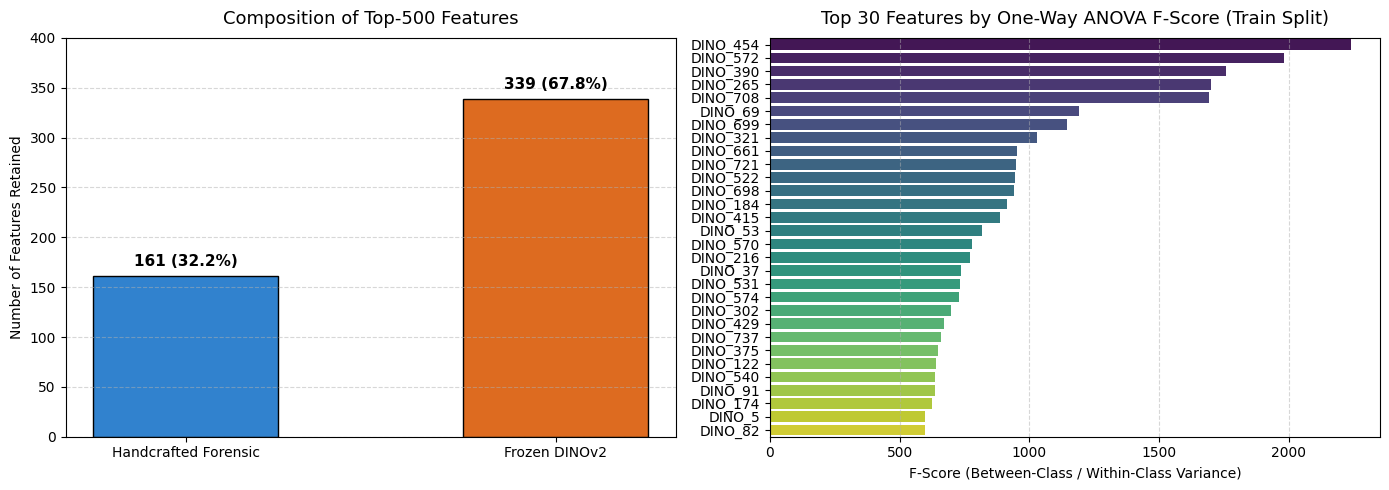


Notebook 01 Complete! You are fully prepared to train scratch models in Notebook 02.


In [9]:
# Verification Plot: Origin composition of Top 500 & Top F-Score rankings
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Feature Origin Breakdown
labels = ['Handcrafted Forensic', 'Frozen DINOv2']
counts = [handcrafted_count, dino_count]
colors = ['#3182ce', '#dd6b20']

axes[0].bar(labels, counts, color=colors, edgecolor='black', width=0.5)
for i, count in enumerate(counts):
    axes[0].text(i, count + 10, f"{count} ({count/500*100:.1f}%)", ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0, 400)
axes[0].set_title("Composition of Top-500 Features", fontsize=13, pad=10)
axes[0].set_ylabel("Number of Features Retained")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Top 30 Highest Discriminative Features (F-Scores)
top30_idx = top500_indices[:30]
top30_scores = f_scores[top30_idx]
top30_labels = [f"DINO_{i-836}" if i >= 836 else f"Hand_{i}" for i in top30_idx]

sns.barplot(x=top30_scores, y=top30_labels, palette="viridis", ax=axes[1])
axes[1].set_title("Top 30 Features by One-Way ANOVA F-Score (Train Split)", fontsize=13, pad=10)
axes[1].set_xlabel("F-Score (Between-Class / Within-Class Variance)")
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "top500_feature_selection_verification.png", dpi=200)
plt.show()

print("\nNotebook 01 Complete! You are fully prepared to train scratch models in Notebook 02.")